# PCA Colored by Physical Variables
## MUC2 Long PTS — Section Cut (Glycosylated vs Non-glycosylated)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.stats import pearsonr

PHYS_DAT = "/home/computer2/analysis_simulations/analysis/physical_variables/physical_vars_sf.dat"
DAT2     = "/home/computer2/analysis_simulations/analysis/pca_combined/pca_coords_sf.dat"
OUT_DIR  = "/home/computer2/analysis_simulations/analysis/pca_physical_vars"
os.makedirs(OUT_DIR, exist_ok=True)

CLR_GLY = "#2E86AB"
CLR_NOG = "#A23B72"
N_GLY   = 2381

print("Ready. Output:", OUT_DIR)

Ready. Output: /home/computer2/analysis_simulations/analysis/pca_physical_vars


## Load Physical Variables

In [2]:
d      = np.genfromtxt(PHYS_DAT, comments="#", dtype=None,
                       encoding="utf-8", names=["rg", "ete", "system"])
rg     = d["rg"].astype(float)
ete    = d["ete"].astype(float)
labels = np.array([s.strip() for s in d["system"]])

print(f"Frames: {len(rg)}  ({np.sum(labels=='glycans')} glycans | {np.sum(labels=='noglycans')} noglycans)")
print(f"Rg  glyc mean: {rg[:N_GLY].mean():.2f} A  |  noglyc mean: {rg[N_GLY:].mean():.2f} A")
print(f"ETE glyc mean: {ete[:N_GLY].mean():.2f} A  |  noglyc mean: {ete[N_GLY:].mean():.2f} A")

Frames: 4762  (2381 glycans | 2381 noglycans)
Rg  glyc mean: 85.74 A  |  noglyc mean: 54.55 A
ETE glyc mean: 279.28 A  |  noglyc mean: 167.08 A


## Load PCA Coordinates

In [3]:
def load_dat(filepath):
    d = np.genfromtxt(filepath, comments="#", dtype=None,
                      encoding="utf-8", names=["pc1", "pc2", "system"])
    return d["pc1"].astype(float), d["pc2"].astype(float)

pc1, pc2 = load_dat(DAT2)
print(f"PCA frames loaded: {len(pc1)}")

PCA frames loaded: 4762


## Plotting Function

In [4]:
def plot_colored(pc1, pc2, color_vals, color_label, cmap, title, outfile):
    fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
    fig.set_facecolor("white")

    vmin = np.percentile(color_vals, 2)
    vmax = np.percentile(color_vals, 98)

    sc = ax.scatter(pc1, pc2, c=color_vals, cmap=cmap,
                    vmin=vmin, vmax=vmax, s=4, alpha=0.75, linewidths=0)

    cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.85)
    cbar.set_label(color_label, fontsize=12,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=10)

    ax.set_title(title, fontsize=13,
                 fontname="DejaVu Serif", fontweight="bold", pad=36)
    ax.set_xlabel("PC1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("PC2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", which="major", labelsize=11,
                   length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    # Place system labels above the clusters in the space between plot and title
    cx_gly = pc1[:N_GLY].mean()
    cx_nog = pc1[N_GLY:].mean()

    # Convert data x to axes fraction for consistent placement
    xlim = ax.get_xlim()
    def to_axes_x(xdata):
        return (xdata - xlim[0]) / (xlim[1] - xlim[0])

    ax.text(to_axes_x(cx_gly), 1.01, "Glycosylated",
            transform=ax.transAxes,
            fontsize=11, fontname="DejaVu Serif", fontweight="bold",
            color=CLR_GLY, ha="center", va="bottom", clip_on=False)

    ax.text(to_axes_x(cx_nog), 1.01, "Non-glycosylated",
            transform=ax.transAxes,
            fontsize=11, fontname="DejaVu Serif", fontweight="bold",
            color=CLR_NOG, ha="center", va="bottom", clip_on=False)

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

print("Function loaded.")

Function loaded.


## Figure 1 — PCA Colored by Radius of Gyration

PC1 vs Rg  r = -0.997


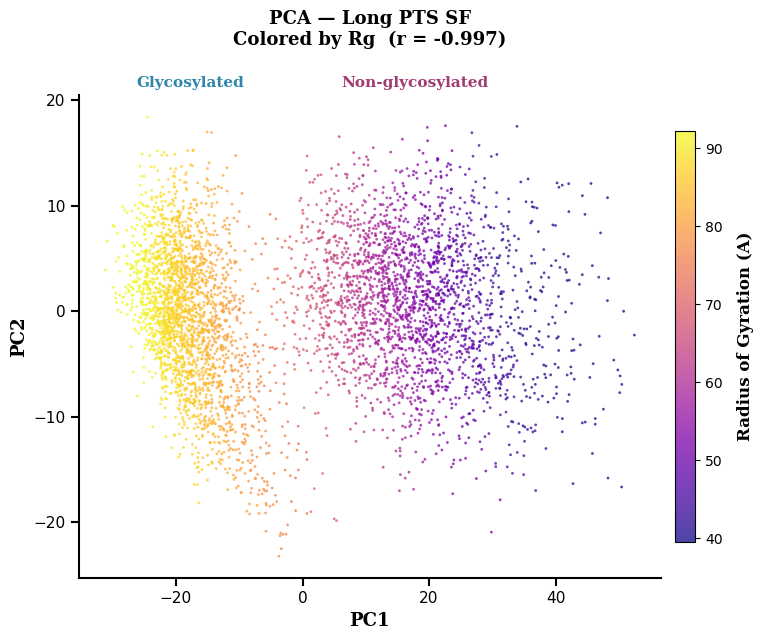

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/pca_sf_rg.png


In [5]:
r_rg, _ = pearsonr(pc1, rg)
print(f"PC1 vs Rg  r = {r_rg:.3f}")

plot_colored(pc1, pc2, rg,
             color_label="Radius of Gyration (A)",
             cmap="plasma",
             title=f"PCA — Long PTS SF\nColored by Rg  (r = {r_rg:.3f})",
             outfile=os.path.join(OUT_DIR, "pca_sf_rg.png"))

## Figure 2 — PCA Colored by End-to-End Distance

PC1 vs ETE r = -0.979


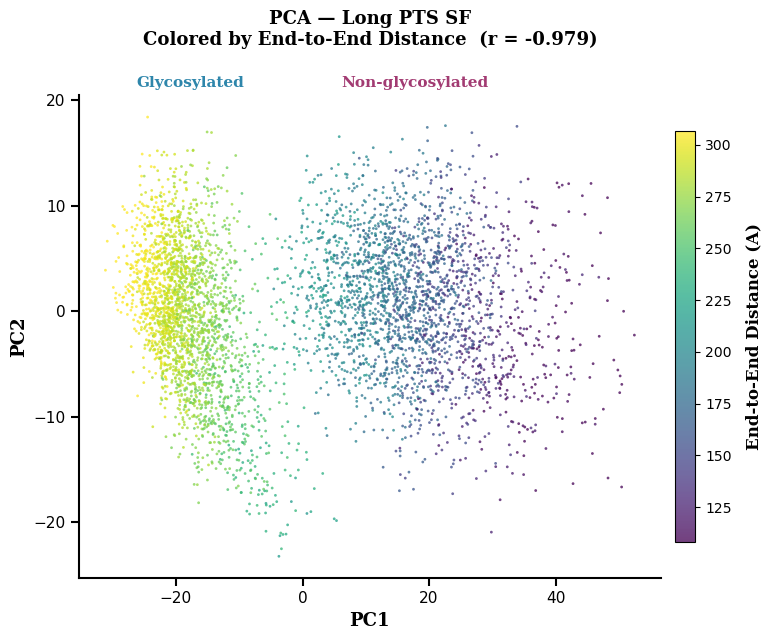

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/pca_sf_ete.png


In [6]:
r_ete, _ = pearsonr(pc1, ete)
print(f"PC1 vs ETE r = {r_ete:.3f}")

plot_colored(pc1, pc2, ete,
             color_label="End-to-End Distance (A)",
             cmap="viridis",
             title=f"PCA — Long PTS SF\nColored by End-to-End Distance  (r = {r_ete:.3f})",
             outfile=os.path.join(OUT_DIR, "pca_sf_ete.png"))

## Figure 3 — Rg and ETE Distributions by System

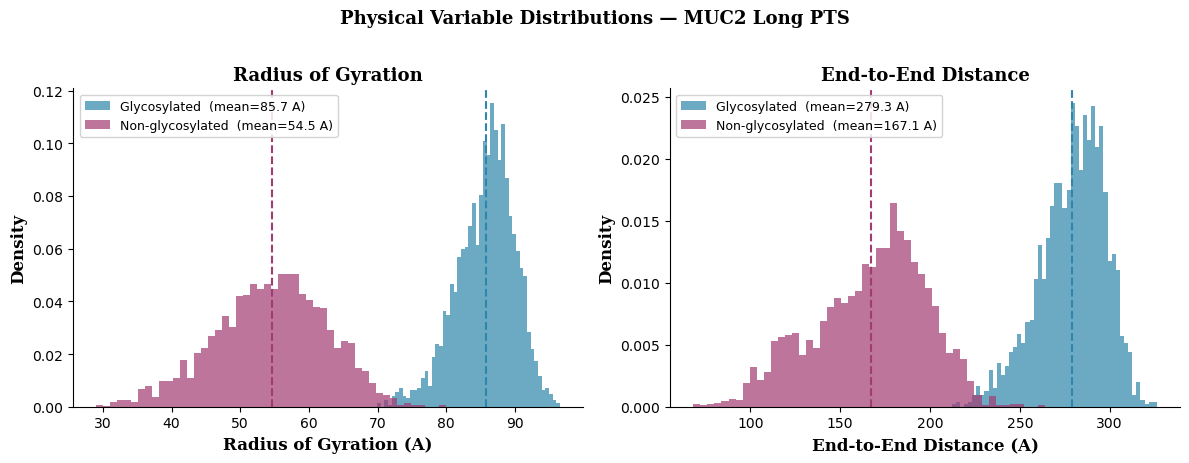

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/distributions_rg_ete.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
fig.set_facecolor("white")

for ax, vals, xlabel in zip(axes,
        [rg,  ete],
        ["Radius of Gyration (A)", "End-to-End Distance (A)"]):
    ax.hist(vals[:N_GLY], bins=50, color=CLR_GLY, alpha=0.7, density=True,
            label=f"Glycosylated  (mean={vals[:N_GLY].mean():.1f} A)")
    ax.hist(vals[N_GLY:], bins=50, color=CLR_NOG, alpha=0.7, density=True,
            label=f"Non-glycosylated  (mean={vals[N_GLY:].mean():.1f} A)")
    ax.axvline(vals[:N_GLY].mean(), color=CLR_GLY, linestyle="--", linewidth=1.5)
    ax.axvline(vals[N_GLY:].mean(), color=CLR_NOG, linestyle="--", linewidth=1.5)
    ax.set_xlabel(xlabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(xlabel.split(" (")[0], fontsize=13,
                 fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, framealpha=0.85)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle("Physical Variable Distributions — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_DIR, "distributions_rg_ete.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — PC1 Correlations with Physical Variables

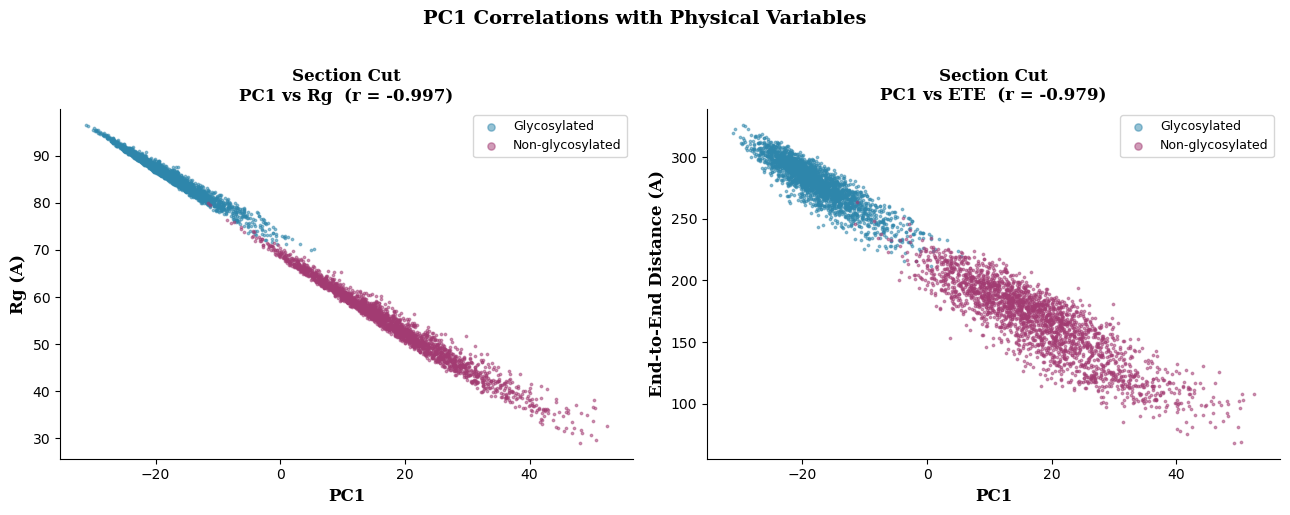

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/pc1_correlations.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

for ax, (vals, ylabel, prop) in zip(axes, [
    (rg,  "Rg (A)",                 "Rg"),
    (ete, "End-to-End Distance (A)", "ETE"),
]):
    r, _ = pearsonr(pc1, vals)
    ax.scatter(pc1[:N_GLY], vals[:N_GLY], s=3, alpha=0.5,
               color=CLR_GLY, label="Glycosylated")
    ax.scatter(pc1[N_GLY:], vals[N_GLY:], s=3, alpha=0.5,
               color=CLR_NOG, label="Non-glycosylated")
    ax.set_xlabel("PC1", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"Section Cut\nPC1 vs {prop}  (r = {r:.3f})",
                 fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, markerscale=3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle("PC1 Correlations with Physical Variables",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_DIR, "pc1_correlations.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: SE Physical Variables (se_physical_vars_sf.dat)
### PCA coordinates with Rg and ETE — pca_combined folder

In [9]:
SE_DAT  = "/home/computer2/analysis_simulations/analysis/pca_combined/se_physical_vars_sf.dat"
OUT_SE  = "/home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots"
os.makedirs(OUT_SE, exist_ok=True)

se_d  = np.genfromtxt(SE_DAT, dtype=None, encoding="utf-8", names=True)
se1   = se_d["SE1"].astype(float)
se2   = se_d["SE2"].astype(float)
se_rg = se_d["Rg_A"].astype(float)
se_ete= se_d["ETE_A"].astype(float)
se_lbl= np.array([s.strip() for s in se_d["system"]])

gly_m = se_lbl == "glycans"
nog_m = se_lbl == "noglycans"

print(f"SE frames: {len(se1)}  ({gly_m.sum()} glycans | {nog_m.sum()} noglycans)")
print(f"SE1 range: {se1.min():.4f} to {se1.max():.4f}")
print(f"SE2 range: {se2.min():.4f} to {se2.max():.4f}")
print(f"Rg  glyc mean: {se_rg[gly_m].mean():.2f} A  |  noglyc mean: {se_rg[nog_m].mean():.2f} A")
print(f"ETE glyc mean: {se_ete[gly_m].mean():.2f} A  |  noglyc mean: {se_ete[nog_m].mean():.2f} A")

SE frames: 4762  (2381 glycans | 2381 noglycans)
SE1 range: -0.0029 to 0.0030
SE2 range: -0.0048 to 0.0126
Rg  glyc mean: 85.74 A  |  noglyc mean: 54.55 A
ETE glyc mean: 279.28 A  |  noglyc mean: 167.08 A


### SE Figure 1 — SE PCA Colored by Rg and ETE (side by side, shared colorbar range)

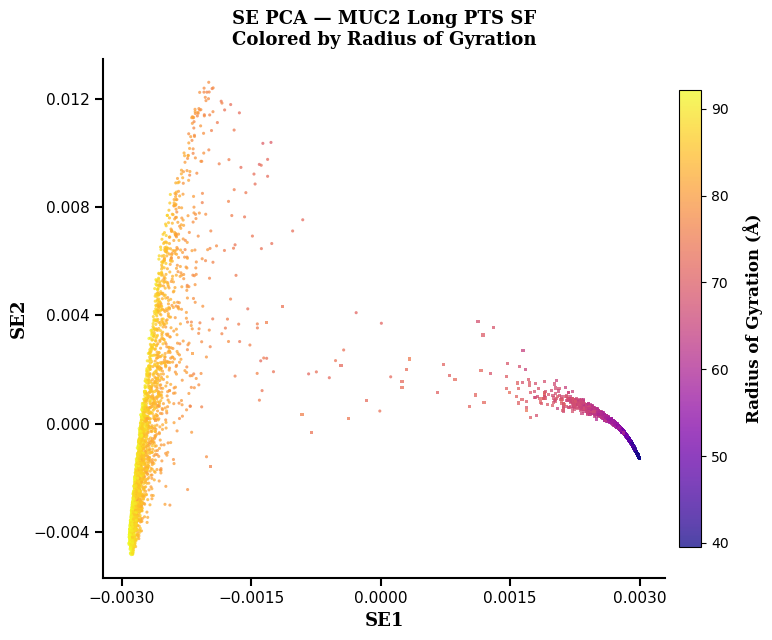

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_pca_rg.png


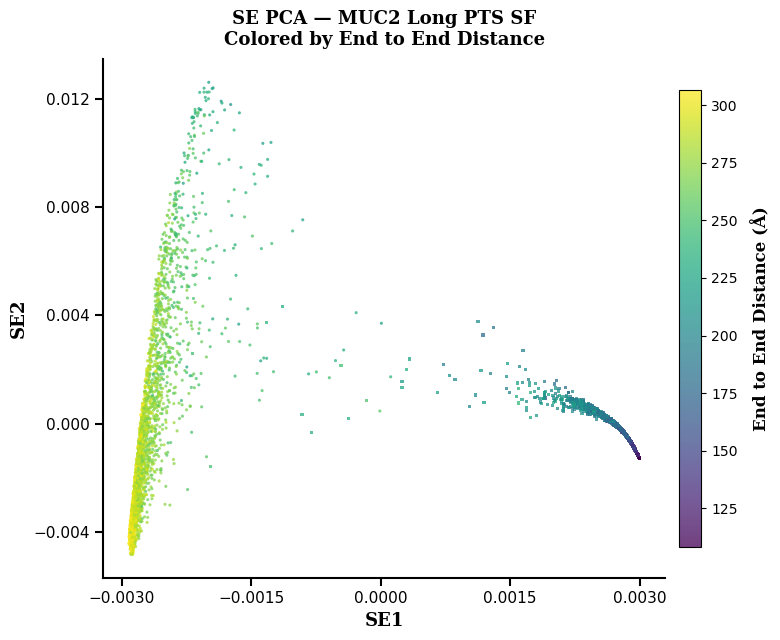

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_pca_ete.png


In [10]:
from scipy.stats import pearsonr

def plot_se_colored(se1, se2, gly_m, nog_m, color_vals, color_label, cmap, title, outfile):
    """Single panel — both systems overlaid, colored by physical variable, shared colorbar."""
    vmin = np.percentile(color_vals, 2)
    vmax = np.percentile(color_vals, 98)

    fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
    fig.set_facecolor("white")

    sc = ax.scatter(se1[gly_m], se2[gly_m], c=color_vals[gly_m],
                    cmap=cmap, vmin=vmin, vmax=vmax,
                    s=5, alpha=0.75, linewidths=0, marker="o")
    ax.scatter(se1[nog_m], se2[nog_m], c=color_vals[nog_m],
               cmap=cmap, vmin=vmin, vmax=vmax,
               s=5, alpha=0.75, linewidths=0, marker="s")

    cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
    cbar.set_label(color_label, fontsize=12,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=10)

    ax.set_xlabel("SE1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("SE2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

# SE PCA colored by Rg
plot_se_colored(se1, se2, gly_m, nog_m,
                color_vals=se_rg,
                color_label="Radius of Gyration (\u00c5)",
                cmap="plasma",
                title="SE PCA \u2014 MUC2 Long PTS SF\nColored by Radius of Gyration",
                outfile=os.path.join(OUT_SE, "se_pca_rg.png"))

# SE PCA colored by ETE
plot_se_colored(se1, se2, gly_m, nog_m,
                color_vals=se_ete,
                color_label="End to End Distance (\u00c5)",
                cmap="viridis",
                title="SE PCA \u2014 MUC2 Long PTS SF\nColored by End to End Distance",
                outfile=os.path.join(OUT_SE, "se_pca_ete.png"))

### SE Figure 2 — Rg and ETE Distributions by System

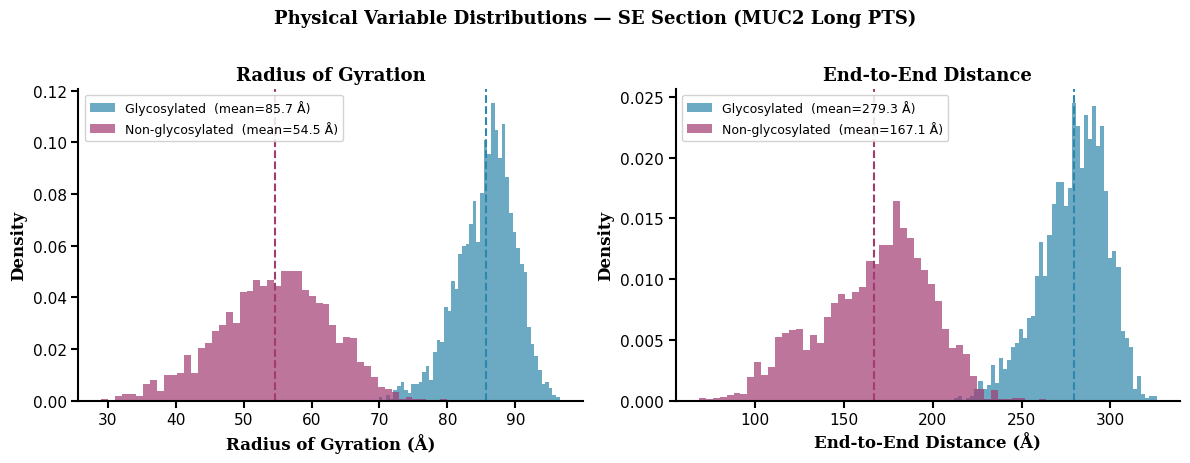

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_distributions_rg_ete.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
fig.set_facecolor("white")

for ax, vals, xlabel in zip(axes,
        [se_rg,  se_ete],
        ["Radius of Gyration (Å)", "End-to-End Distance (Å)"]):
    ax.hist(vals[gly_m], bins=50, color=CLR_GLY, alpha=0.7, density=True,
            label=f"Glycosylated  (mean={vals[gly_m].mean():.1f} Å)")
    ax.hist(vals[nog_m], bins=50, color=CLR_NOG, alpha=0.7, density=True,
            label=f"Non-glycosylated  (mean={vals[nog_m].mean():.1f} Å)")
    ax.axvline(vals[gly_m].mean(), color=CLR_GLY, linestyle="--", linewidth=1.5)
    ax.axvline(vals[nog_m].mean(), color=CLR_NOG, linestyle="--", linewidth=1.5)
    ax.set_xlabel(xlabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(xlabel.split(" (")[0], fontsize=13,
                 fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, framealpha=0.85)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.suptitle("Physical Variable Distributions — SE Section (MUC2 Long PTS)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_SE, "se_distributions_rg_ete.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: SE Curvature (se_curvature_all.dat)
### SE PCA coordinates colored by RMS curvature (kappa, degrees)

In [12]:
CURV_DAT = "/home/computer2/analysis_simulations/analysis/pca_combined/se_curvature_all.dat"
LP_DAT   = "/home/computer2/analysis_simulations/analysis/pca_combined/se_lp_all.dat"
OUT_SE2  = "/home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots"
os.makedirs(OUT_SE2, exist_ok=True)

# ── Curvature file ────────────────────────────────────────────────────────────
curv = np.genfromtxt(CURV_DAT, comments="#")
# cols: global_frame  SE1  SE2  kappa_rms_rad  kappa_rms_deg  system(ignored)
se1_c   = curv[:, 1]
se2_c   = curv[:, 2]
kap_rad = curv[:, 3]
kap_deg = curv[:, 4]

# system split: first 2381 = glycans, next 2381 = noglycans
N_GLY = 2381
c_gly = slice(0, N_GLY)
c_nog = slice(N_GLY, None)

print("=== se_curvature_all.dat ===")
print(f"Frames: {len(se1_c)}  ({N_GLY} glycans | {len(se1_c)-N_GLY} noglycans)")
print(f"kappa_rms_deg  glyc: {kap_deg[c_gly].mean():.2f} ± {kap_deg[c_gly].std():.2f}°")
print(f"kappa_rms_deg  noglyc: {kap_deg[c_nog].mean():.2f} ± {kap_deg[c_nog].std():.2f}°")

# ── LP file ───────────────────────────────────────────────────────────────────
lp = np.genfromtxt(LP_DAT, comments="#")
# cols: global_frame  SE1  SE2  Lp_mean_A  Lp_mean_nm  Lp_std_A  system(ignored)
se1_l  = lp[:, 1]
se2_l  = lp[:, 2]
lp_A   = lp[:, 3]
lp_nm  = lp[:, 4]
lp_std = lp[:, 5]

print("\n=== se_lp_all.dat ===")
print(f"Frames: {len(se1_l)}  ({N_GLY} glycans | {len(se1_l)-N_GLY} noglycans)")
print(f"Lp_mean_A  glyc:   {lp_A[c_gly].mean():.4f} Å  (constant within system)")
print(f"Lp_mean_A  noglyc: {lp_A[c_nog].mean():.4f} Å  (constant within system)")

=== se_curvature_all.dat ===
Frames: 4762  (2381 glycans | 2381 noglycans)
kappa_rms_deg  glyc: 121.75 ± 0.95°
kappa_rms_deg  noglyc: 116.85 ± 1.24°

=== se_lp_all.dat ===
Frames: 4762  (2381 glycans | 2381 noglycans)
Lp_mean_A  glyc:   35.5540 Å  (constant within system)
Lp_mean_A  noglyc: 12.1432 Å  (constant within system)


### Curvature Figure 1 — SE PCA colored by RMS Curvature (°)

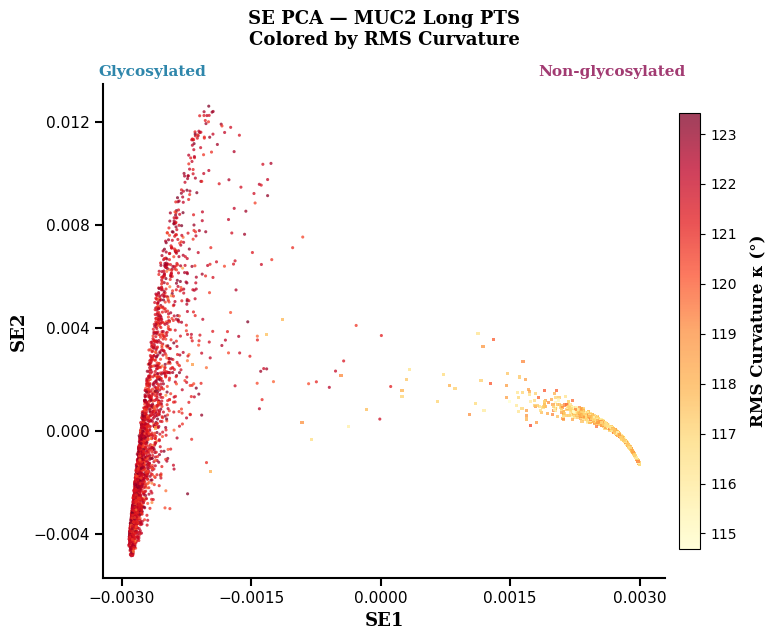

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_pca_curvature.png
SE1 vs curvature  r:  glyc=-0.033  noglyc=-0.179


In [13]:
from scipy.stats import pearsonr

r_curv_gly, _ = pearsonr(se1_c[c_gly], kap_deg[c_gly])
r_curv_nog, _ = pearsonr(se1_c[c_nog], kap_deg[c_nog])

# ── Scatter: both systems, colored by curvature ───────────────────────────────
vmin_k = np.percentile(kap_deg, 2)
vmax_k = np.percentile(kap_deg, 98)

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
fig.set_facecolor("white")

sc = ax.scatter(se1_c[c_gly], se2_c[c_gly], c=kap_deg[c_gly],
                cmap="YlOrRd", vmin=vmin_k, vmax=vmax_k,
                s=5, alpha=0.75, linewidths=0, marker="o")
ax.scatter(se1_c[c_nog], se2_c[c_nog], c=kap_deg[c_nog],
           cmap="YlOrRd", vmin=vmin_k, vmax=vmax_k,
           s=5, alpha=0.75, linewidths=0, marker="s")

cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label("RMS Curvature κ (°)", fontsize=12,
               fontname="DejaVu Serif", fontweight="bold", labelpad=10)
cbar.ax.tick_params(labelsize=10)

# System labels above clusters
cx_gly = se1_c[c_gly].mean();  cx_nog = se1_c[c_nog].mean()
xlim = ax.get_xlim()
def to_ax(x): return (x - xlim[0]) / (xlim[1] - xlim[0])
ax.text(to_ax(cx_gly), 1.01, "Glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_GLY, ha="center", va="bottom", clip_on=False)
ax.text(to_ax(cx_nog), 1.01, "Non-glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_NOG, ha="center", va="bottom", clip_on=False)

ax.set_xlabel("SE1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("SE2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("SE PCA — MUC2 Long PTS\nColored by RMS Curvature",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=28)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

plt.tight_layout()
out = os.path.join(OUT_SE2, "se_pca_curvature.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")
print(f"SE1 vs curvature  r:  glyc={r_curv_gly:.3f}  noglyc={r_curv_nog:.3f}")

### Curvature Figure 2 — Distribution of RMS Curvature by System

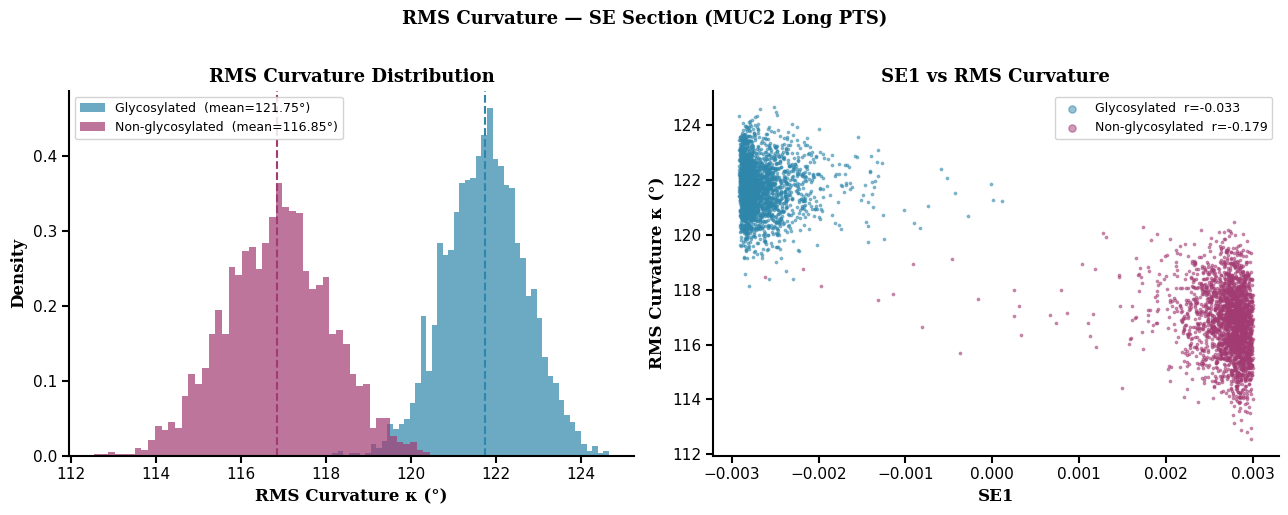

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_curvature_distribution.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

# Left: histogram distribution
ax = axes[0]
ax.hist(kap_deg[c_gly], bins=50, color=CLR_GLY, alpha=0.7, density=True,
        label=f"Glycosylated  (mean={kap_deg[c_gly].mean():.2f}°)")
ax.hist(kap_deg[c_nog], bins=50, color=CLR_NOG, alpha=0.7, density=True,
        label=f"Non-glycosylated  (mean={kap_deg[c_nog].mean():.2f}°)")
ax.axvline(kap_deg[c_gly].mean(), color=CLR_GLY, linestyle="--", linewidth=1.5)
ax.axvline(kap_deg[c_nog].mean(), color=CLR_NOG, linestyle="--", linewidth=1.5)
ax.set_xlabel("RMS Curvature κ (°)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("RMS Curvature Distribution", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=9, framealpha=0.85)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

# Right: SE1 vs curvature scatter
ax = axes[1]
ax.scatter(se1_c[c_gly], kap_deg[c_gly], s=3, alpha=0.5,
           color=CLR_GLY, label=f"Glycosylated  r={r_curv_gly:.3f}")
ax.scatter(se1_c[c_nog], kap_deg[c_nog], s=3, alpha=0.5,
           color=CLR_NOG, label=f"Non-glycosylated  r={r_curv_nog:.3f}")
ax.set_xlabel("SE1", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMS Curvature κ (°)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("SE1 vs RMS Curvature", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=9, markerscale=3, framealpha=0.85)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.suptitle("RMS Curvature — SE Section (MUC2 Long PTS)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_SE2, "se_curvature_distribution.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: SE Persistence Length (se_lp_all.dat)
### SE PCA coordinates colored by mean persistence length (Lp, Å)
Note: Lp_mean_A is a single mean over all residues, constant across frames within each system.

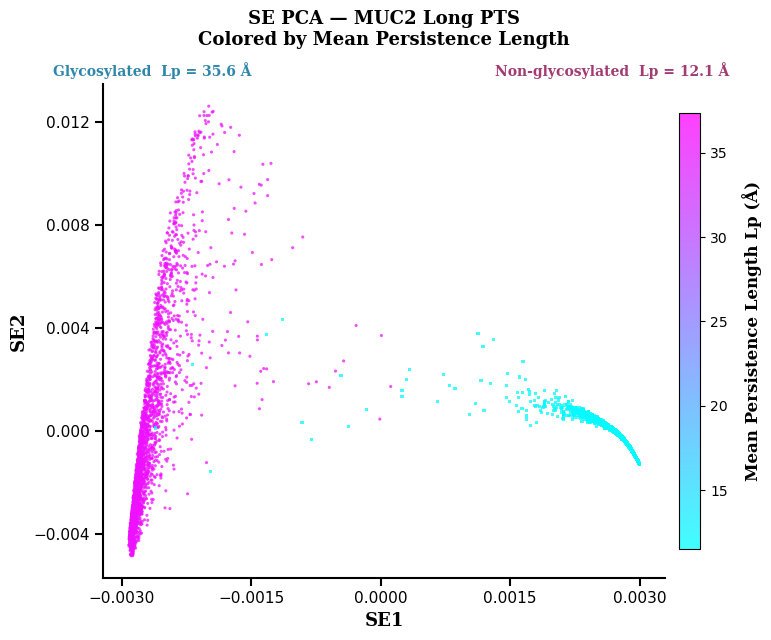

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/se_plots/se_pca_lp.png


In [15]:
# ── Scatter: SE colored by Lp ─────────────────────────────────────────────────
vmin_lp = lp_A.min() * 0.95
vmax_lp = lp_A.max() * 1.05

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
fig.set_facecolor("white")

sc = ax.scatter(se1_l[c_gly], se2_l[c_gly], c=lp_A[c_gly],
                cmap="cool", vmin=vmin_lp, vmax=vmax_lp,
                s=5, alpha=0.75, linewidths=0, marker="o")
ax.scatter(se1_l[c_nog], se2_l[c_nog], c=lp_A[c_nog],
           cmap="cool", vmin=vmin_lp, vmax=vmax_lp,
           s=5, alpha=0.75, linewidths=0, marker="s")

cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label("Mean Persistence Length Lp (Å)", fontsize=12,
               fontname="DejaVu Serif", fontweight="bold", labelpad=10)
cbar.ax.tick_params(labelsize=10)

# Annotate each cluster with its Lp value
lp_gly_val = lp_A[c_gly].mean()
lp_nog_val = lp_A[c_nog].mean()

cx_gly = se1_l[c_gly].mean();  cy_gly = se2_l[c_gly].mean()
cx_nog = se1_l[c_nog].mean();  cy_nog = se2_l[c_nog].mean()
xlim = ax.get_xlim()
def to_ax2(x): return (x - xlim[0]) / (xlim[1] - xlim[0])

ax.text(to_ax2(cx_gly), 1.01, f"Glycosylated  Lp = {lp_gly_val:.1f} Å",
        transform=ax.transAxes, fontsize=10, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_GLY, ha="center", va="bottom", clip_on=False)
ax.text(to_ax2(cx_nog), 1.01, f"Non-glycosylated  Lp = {lp_nog_val:.1f} Å",
        transform=ax.transAxes, fontsize=10, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_NOG, ha="center", va="bottom", clip_on=False)

ax.set_xlabel("SE1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("SE2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("SE PCA — MUC2 Long PTS\nColored by Mean Persistence Length",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=28)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

plt.tight_layout()
out = os.path.join(OUT_SE2, "se_pca_lp.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: Free Energy Surface (se_longpts_fes/)
### FES = −kT·ln(P), shifted so minimum = 0 within each system
- **Low FES (≈ 0 kcal/mol)** = most frequently visited = thermodynamically stable conformation
- **High FES** = rarely visited = unstable or entropically costly conformation
- kT = 0.596 kcal/mol at 300 K

In [16]:
FES_BASE = "/home/computer2/analysis_simulations/analysis/se_longpts_fes/"
OUT_FES  = "/home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_plots"
os.makedirs(OUT_FES, exist_ok=True)

# Individual system files: cols = frame_index  SE1  SE2  FES_kcal_mol
fes_gly = np.genfromtxt(FES_BASE + "se_fes_glycans.dat",   comments="#")
fes_nog = np.genfromtxt(FES_BASE + "se_fes_noglycans.dat", comments="#")

se1_fg = fes_gly[:, 1];  se2_fg = fes_gly[:, 2];  fes_g = fes_gly[:, 3]
se1_fn = fes_nog[:, 1];  se2_fn = fes_nog[:, 2];  fes_n = fes_nog[:, 3]

print(f"Glycosylated   frames: {len(fes_g)}  FES range: {fes_g.min():.3f} – {fes_g.max():.3f} kcal/mol")
print(f"Non-glycosylated frames: {len(fes_n)}  FES range: {fes_n.min():.3f} – {fes_n.max():.3f} kcal/mol")

# Shared colorbar max = 98th percentile across both systems
fes_vmax = np.percentile(np.concatenate([fes_g, fes_n]), 98)
print(f"Shared vmax (98th pct): {fes_vmax:.3f} kcal/mol")

Glycosylated   frames: 2381  FES range: 0.000 – 3.866 kcal/mol
Non-glycosylated frames: 2381  FES range: 0.000 – 3.829 kcal/mol
Shared vmax (98th pct): 3.086 kcal/mol


### FES Figure 1 — SE PCA Colored by Free Energy (side-by-side, shared scale)

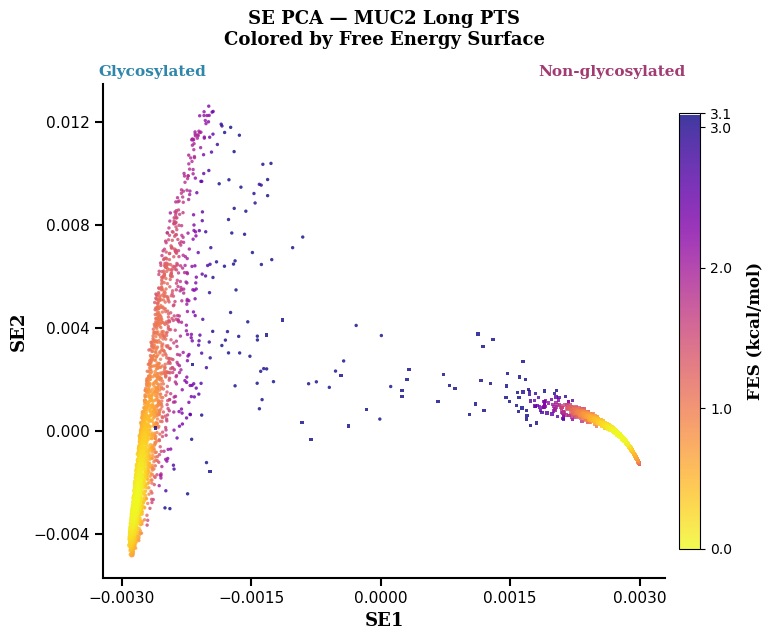

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_plots/se_fes_scatter.png


In [17]:
# Combined arrays for both systems
se1_fes_all = np.concatenate([se1_fg, se1_fn])
se2_fes_all = np.concatenate([se2_fg, se2_fn])
fes_all     = np.concatenate([fes_g,  fes_n])
fes_gly_m   = np.zeros(len(fes_all), dtype=bool); fes_gly_m[:len(fes_g)] = True
fes_nog_m   = ~fes_gly_m

# Shared colour scale: 0 (most stable) to 98th percentile
fes_vmax = np.percentile(fes_all, 98)

# Sort so low-FES (stable) points render on top
order = np.argsort(fes_all)[::-1]

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
fig.set_facecolor("white")

sc = ax.scatter(se1_fes_all[order][fes_gly_m[order]],
                se2_fes_all[order][fes_gly_m[order]],
                c=fes_all[order][fes_gly_m[order]],
                cmap="plasma_r", vmin=0, vmax=fes_vmax,
                s=6, alpha=0.80, linewidths=0, marker="o")
ax.scatter(se1_fes_all[order][fes_nog_m[order]],
           se2_fes_all[order][fes_nog_m[order]],
           c=fes_all[order][fes_nog_m[order]],
           cmap="plasma_r", vmin=0, vmax=fes_vmax,
           s=6, alpha=0.80, linewidths=0, marker="s")

cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label("FES (kcal/mol)", fontsize=12,
               fontname="DejaVu Serif", fontweight="bold", labelpad=10)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks([0, 1, 2, 3, round(fes_vmax, 1)])

# System labels above each cluster (matching PCA plot style)
cx_gly = se1_fg.mean(); cx_nog = se1_fn.mean()
xlim = ax.get_xlim()
def fes_to_ax(x): return (x - xlim[0]) / (xlim[1] - xlim[0])
ax.text(fes_to_ax(cx_gly), 1.01, "Glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_GLY, ha="center", va="bottom", clip_on=False)
ax.text(fes_to_ax(cx_nog), 1.01, "Non-glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_NOG, ha="center", va="bottom", clip_on=False)

ax.set_xlabel("SE1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("SE2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("SE PCA — MUC2 Long PTS\nColored by Free Energy Surface",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=28)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

plt.tight_layout()
out = os.path.join(OUT_FES, "se_fes_scatter.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

### FES Figure 2 — 2D Free Energy Landscape (hexbin grid)

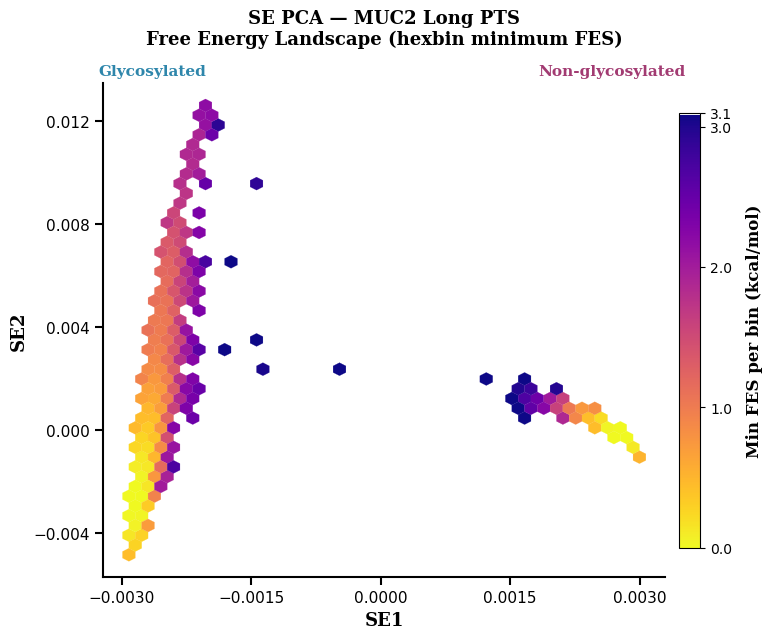

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_plots/se_fes_hexbin.png


In [18]:
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=100)
fig.set_facecolor("white")

# Combined hexbin — both systems on same axes, white background
hb = ax.hexbin(se1_fes_all, se2_fes_all, C=fes_all,
               reduce_C_function=np.min,
               gridsize=40, cmap="plasma_r",
               vmin=0, vmax=fes_vmax,
               linewidths=0.15, mincnt=1)

cbar = plt.colorbar(hb, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label("Min FES per bin (kcal/mol)", fontsize=12,
               fontname="DejaVu Serif", fontweight="bold", labelpad=10)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks([0, 1, 2, 3, round(fes_vmax, 1)])

# System labels
xlim = ax.get_xlim()
ax.text(fes_to_ax(cx_gly), 1.01, "Glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_GLY, ha="center", va="bottom", clip_on=False)
ax.text(fes_to_ax(cx_nog), 1.01, "Non-glycosylated",
        transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
        fontweight="bold", color=CLR_NOG, ha="center", va="bottom", clip_on=False)

ax.set_xlabel("SE1", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("SE2", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("SE PCA — MUC2 Long PTS\nFree Energy Landscape (hexbin minimum FES)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=28)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

plt.tight_layout()
out = os.path.join(OUT_FES, "se_fes_hexbin.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

### FES Figure 3 — FES Distribution by System

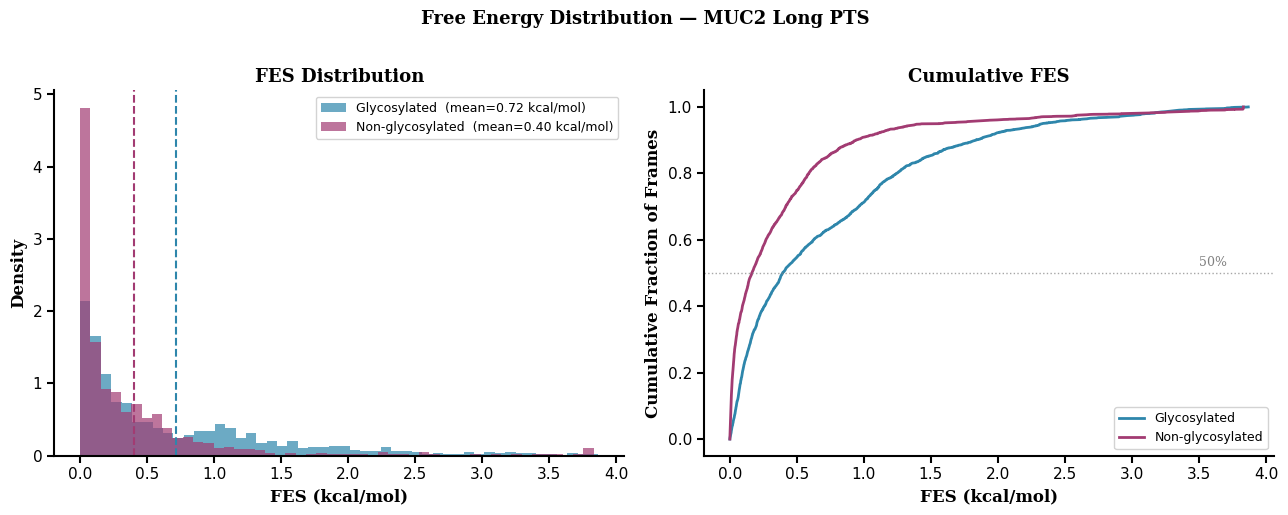

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_plots/se_fes_distribution.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

# Left: FES histogram
ax = axes[0]
ax.hist(fes_g, bins=50, color=CLR_GLY, alpha=0.7, density=True,
        label=f"Glycosylated  (mean={fes_g.mean():.2f} kcal/mol)")
ax.hist(fes_n, bins=50, color=CLR_NOG, alpha=0.7, density=True,
        label=f"Non-glycosylated  (mean={fes_n.mean():.2f} kcal/mol)")
ax.axvline(fes_g.mean(), color=CLR_GLY, linestyle="--", linewidth=1.5)
ax.axvline(fes_n.mean(), color=CLR_NOG, linestyle="--", linewidth=1.5)
ax.set_xlabel("FES (kcal/mol)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("FES Distribution", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=9, framealpha=0.85)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

# Right: cumulative FES — fraction of frames below a given energy
ax = axes[1]
for fes, label, col in [(fes_g, "Glycosylated", CLR_GLY),
                         (fes_n, "Non-glycosylated", CLR_NOG)]:
    fes_sorted = np.sort(fes)
    cdf = np.arange(1, len(fes_sorted) + 1) / len(fes_sorted)
    ax.plot(fes_sorted, cdf, color=col, linewidth=2.0, label=label)

ax.axhline(0.5, color="gray", linewidth=1.0, linestyle=":", alpha=0.7)
ax.text(3.5, 0.52, "50%", fontsize=9, color="gray", fontname="DejaVu Serif")
ax.set_xlabel("FES (kcal/mol)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Cumulative Fraction of Frames", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Cumulative FES", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=9, framealpha=0.85)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.suptitle("Free Energy Distribution — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_FES, "se_fes_distribution.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: Three-System PCA Analysis
### pca_coords_3sys.dat + physical_vars_3sys.dat (glycans | noglycans | ext_glycans)

In [20]:
from scipy.stats import pearsonr

BASE_3SYS = "/home/computer2/analysis_simulations/analysis/physical_variables/pca_threesystems/"
OUT_3SYS  = "/home/computer2/analysis_simulations/analysis/pca_physical_vars/threesys_plots"
os.makedirs(OUT_3SYS, exist_ok=True)

CLR_EXT = "#F18F01"   # amber/orange for ext_glycans
N_SYS   = 2381        # frames per system

# ── Load PCA coordinates ──────────────────────────────────────────────────────
pca3 = np.genfromtxt(BASE_3SYS + "pca_coords_3sys.dat", comments="#",
                     dtype=None, encoding="utf-8",
                     names=["pc1", "pc2", "system"])
pc1_3 = pca3["pc1"].astype(float)
pc2_3 = pca3["pc2"].astype(float)
lbl_3 = np.array([s.strip() for s in pca3["system"]])

gly_m3 = lbl_3 == "glycans"
nog_m3 = lbl_3 == "noglycans"
ext_m3 = lbl_3 == "ext_glycans"

# ── Load physical variables ───────────────────────────────────────────────────
phys3 = np.genfromtxt(BASE_3SYS + "physical_vars_3sys.dat", comments="#",
                      dtype=None, encoding="utf-8",
                      names=["rg", "ete", "system"])
rg3  = phys3["rg"].astype(float)
ete3 = phys3["ete"].astype(float)

print(f"Frames: {len(pc1_3)}  ({gly_m3.sum()} glycans | {nog_m3.sum()} noglycans | {ext_m3.sum()} ext_glycans)")
print(f"Rg  glyc={rg3[gly_m3].mean():.2f} Å  nog={rg3[nog_m3].mean():.2f} Å  ext={rg3[ext_m3].mean():.2f} Å")
print(f"ETE glyc={ete3[gly_m3].mean():.2f} Å  nog={ete3[nog_m3].mean():.2f} Å  ext={ete3[ext_m3].mean():.2f} Å")

Frames: 7143  (2381 glycans | 2381 noglycans | 2381 ext_glycans)
Rg  glyc=85.74 Å  nog=54.55 Å  ext=98.66 Å
ETE glyc=279.28 Å  nog=167.08 Å  ext=323.34 Å


### 3-System Figure 1 — PCA Colored by Rg and ETE

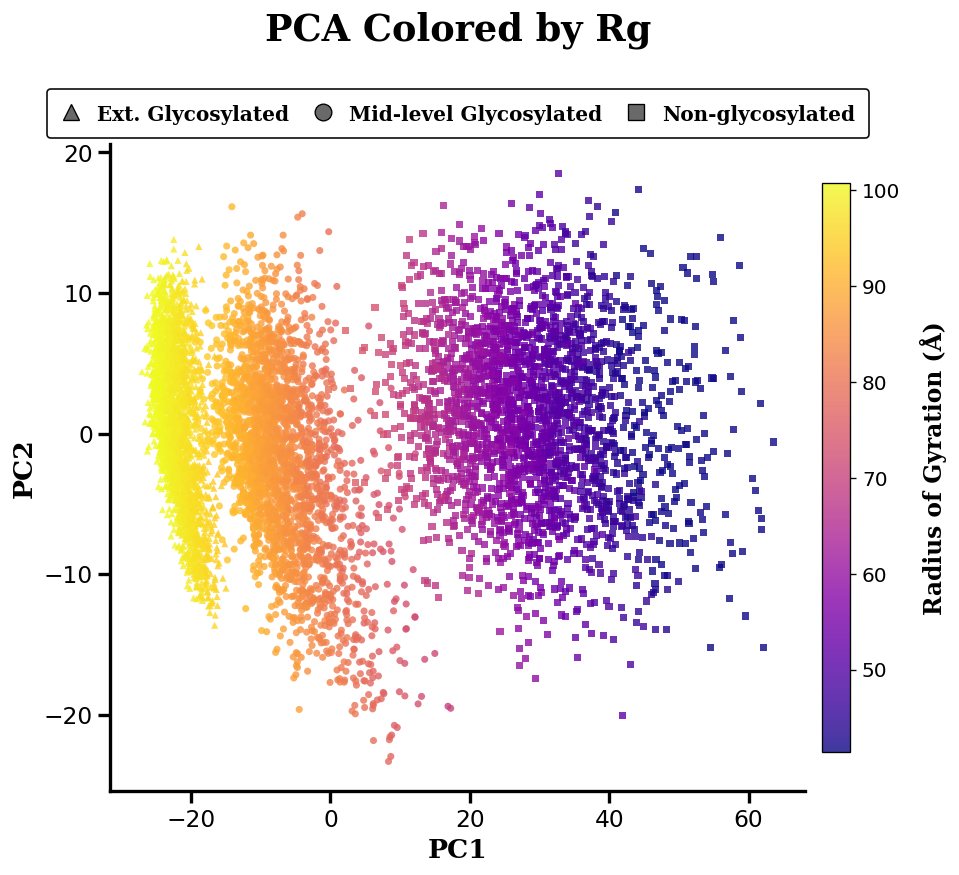

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/threesys_plots/3sys_pca_rg.png


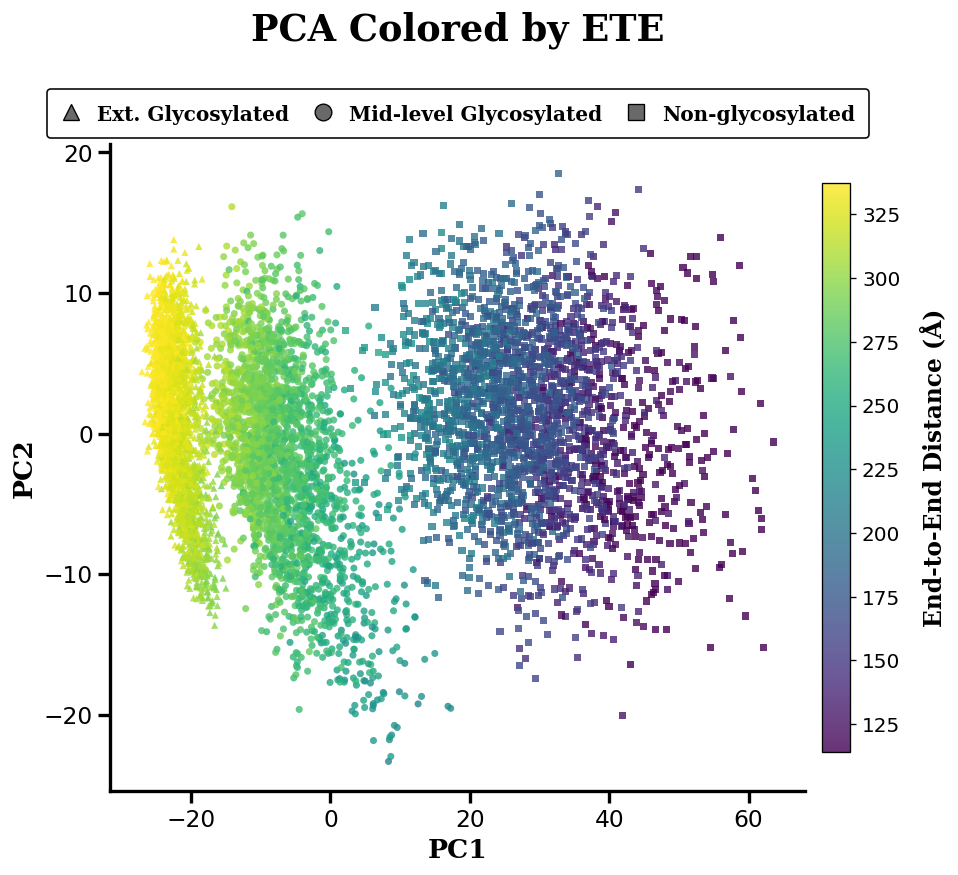

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/threesys_plots/3sys_pca_ete.png


In [21]:
import matplotlib.lines as mlines

def plot_3sys_colored(pc1, pc2, gly_m, nog_m, ext_m, color_vals,
                      color_label, cmap, title, outfile):
    """
    Three systems overlaid, colored by physical variable, shared colorbar.
    Legend uses marker shapes (not system colors) since scatter color = colormap value.
    Legend order: Ext. Glycosylated -> Mid-level Glycosylated -> Non-glycosylated.
    """
    vmin = np.percentile(color_vals, 2)
    vmax = np.percentile(color_vals, 98)

    fig, ax = plt.subplots(figsize=(9, 7), dpi=120)
    fig.set_facecolor("white")

    # Canonical scatter order: nog background -> gly -> ext on top
    for mask, marker in [(nog_m, "s"), (gly_m, "o"), (ext_m, "^")]:
        sc = ax.scatter(pc1[mask], pc2[mask], c=color_vals[mask],
                        cmap=cmap, vmin=vmin, vmax=vmax,
                        s=18, alpha=0.80, linewidths=0, marker=marker)

    cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
    cbar.set_label(color_label, fontsize=14,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=12)
    cbar.ax.tick_params(labelsize=12)

    # Marker-based legend — distinguishes systems by SHAPE, not color,
    # since scatter color encodes the continuous physical variable (Rg / ETE)
    legend_handles = [
        mlines.Line2D([], [], color="dimgrey", marker="^", linestyle="None",
                      markersize=10, markeredgecolor="black", markeredgewidth=0.8,
                      label="Ext. Glycosylated"),
        mlines.Line2D([], [], color="dimgrey", marker="o", linestyle="None",
                      markersize=10, markeredgecolor="black", markeredgewidth=0.8,
                      label="Mid-level Glycosylated"),
        mlines.Line2D([], [], color="dimgrey", marker="s", linestyle="None",
                      markersize=10, markeredgecolor="black", markeredgewidth=0.8,
                      label="Non-glycosylated"),
    ]
    ax.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.10),
        ncol=3,
        fontsize=12,
        frameon=True,
        framealpha=0.95,
        edgecolor="black",
        handlelength=1.0,
        handleheight=1.2,
        borderpad=0.7,
        columnspacing=1.2,
        prop={"family": "DejaVu Serif", "size": 12, "weight": "bold"},
    )

    ax.set_xlabel("PC1", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("PC2", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=22, fontname="DejaVu Serif",
                 fontweight="bold", pad=62)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")


# PCA colored by Rg
plot_3sys_colored(pc1_3, pc2_3, gly_m3, nog_m3, ext_m3,
                  color_vals=rg3,
                  color_label="Radius of Gyration (\u00c5)",
                  cmap="plasma",
                  title="PCA Colored by Rg",
                  outfile=os.path.join(OUT_3SYS, "3sys_pca_rg.png"))

# PCA colored by ETE
plot_3sys_colored(pc1_3, pc2_3, gly_m3, nog_m3, ext_m3,
                  color_vals=ete3,
                  color_label="End-to-End Distance (\u00c5)",
                  cmap="viridis",
                  title="PCA Colored by ETE",
                  outfile=os.path.join(OUT_3SYS, "3sys_pca_ete.png"))


### 3-System Figure 2 — Rg and ETE Distributions

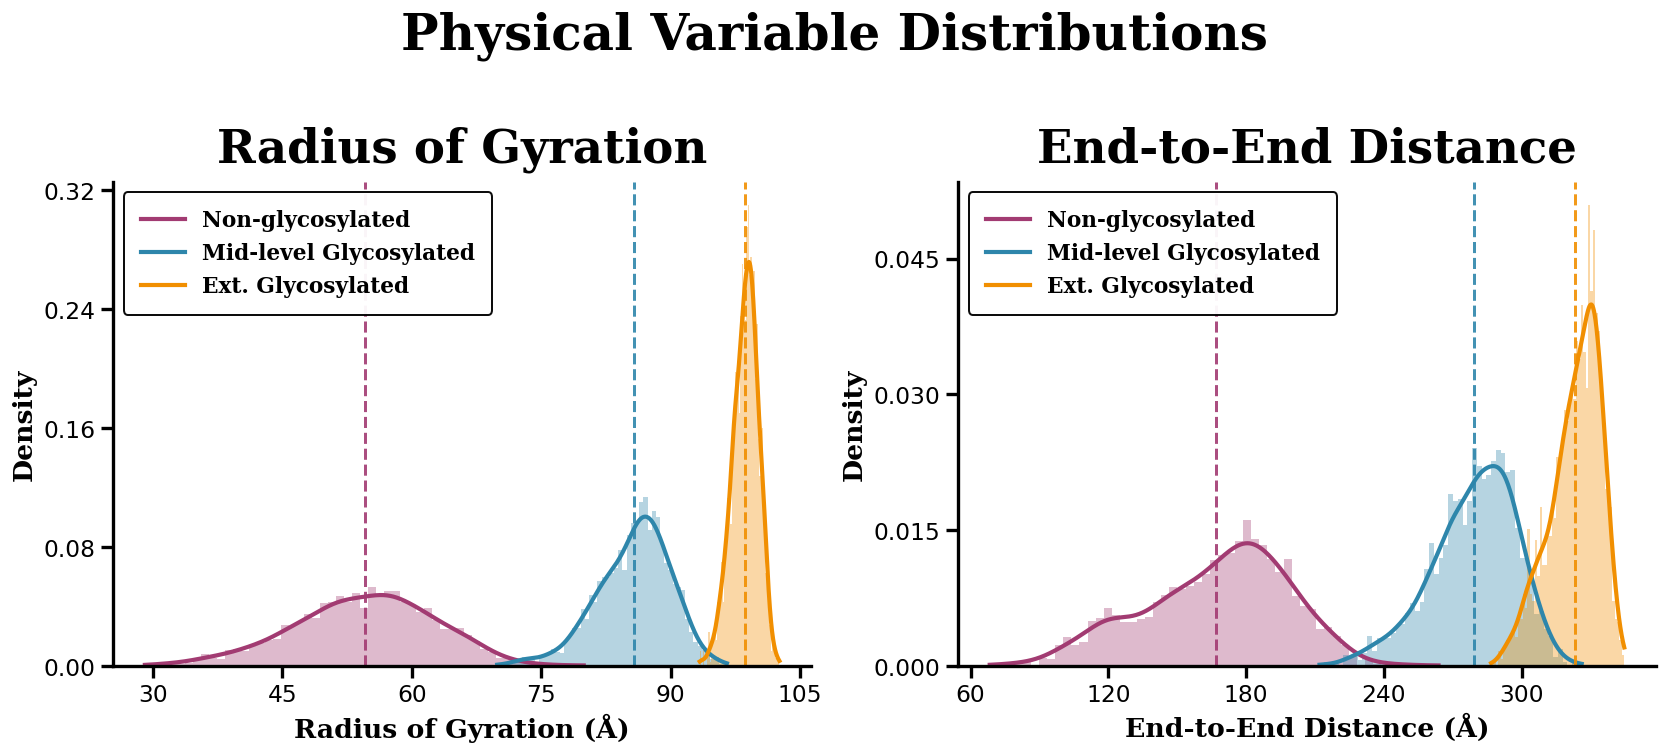

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/threesys_plots/3sys_distributions_rg_ete.png


In [22]:
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=120)
fig.set_facecolor("white")

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
systems3 = [
    (nog_m3, "Non-glycosylated",      CLR_NOG),
    (gly_m3, "Mid-level Glycosylated", CLR_GLY),
    (ext_m3, "Ext. Glycosylated",      CLR_EXT),
]

for ax, vals, xlabel in zip(axes,
        [rg3, ete3],
        ["Radius of Gyration (\u00c5)", "End-to-End Distance (\u00c5)"]):

    for mask, label, clr in systems3:
        data = vals[mask]
        mean_val = data.mean()

        # Filled histogram
        ax.hist(data, bins=55, color=clr, alpha=0.35, density=True,
                edgecolor="none")

        # KDE curve on top for clarity
        kde = gaussian_kde(data, bw_method=0.25)
        x_range = np.linspace(data.min(), data.max(), 400)
        ax.plot(x_range, kde(x_range), color=clr, linewidth=2.5, label=label)

        # Mean dashed line
        ax.axvline(mean_val, color=clr, linestyle="--", linewidth=1.8, alpha=0.9)

    ax.set_xlabel(xlabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(xlabel.split(" (")[0], fontsize=28,
                 fontname="DejaVu Serif", fontweight="bold", pad=12)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0)
    ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MaxNLocator(6))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))
    leg = ax.legend(
        fontsize=13,
        frameon=True,
        framealpha=0.95,
        edgecolor="black",
        borderpad=0.8,
        prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"},
    )
    leg.get_frame().set_linewidth(1.2)

plt.suptitle("Physical Variable Distributions",
             fontsize=30, fontname="DejaVu Serif", fontweight="bold", y=1.04)
plt.tight_layout()
out = os.path.join(OUT_3SYS, "3sys_distributions_rg_ete.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


### 3-System Figure 3 — PC1 Correlations with Physical Variables

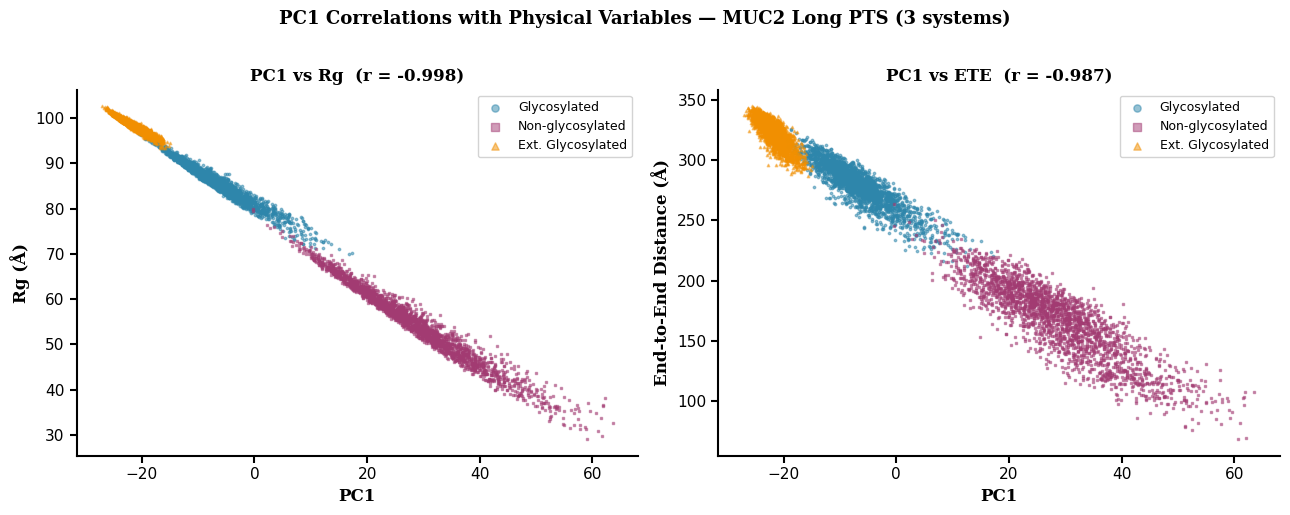

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/threesys_plots/3sys_pc1_correlations.png


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

for ax, (vals, ylabel, prop) in zip(axes, [
    (rg3,  "Rg (Å)",                 "Rg"),
    (ete3, "End-to-End Distance (Å)", "ETE"),
]):
    r, _ = pearsonr(pc1_3, vals)
    for mask, label, clr, mkr in [
        (gly_m3, "Glycosylated",      CLR_GLY, "o"),
        (nog_m3, "Non-glycosylated",  CLR_NOG, "s"),
        (ext_m3, "Ext. Glycosylated", CLR_EXT, "^"),
    ]:
        ax.scatter(pc1_3[mask], vals[mask], s=3, alpha=0.5,
                   color=clr, marker=mkr, label=label)
    ax.set_xlabel("PC1", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"PC1 vs {prop}  (r = {r:.3f})",
                 fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, markerscale=3, framealpha=0.85)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.suptitle("PC1 Correlations with Physical Variables — MUC2 Long PTS (3 systems)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(OUT_3SYS, "3sys_pc1_correlations.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Section: Free Energy Surface — 3 Systems (SE & PCA coordinates)
### Individual (one panel per system) and Group (all systems combined)
### Source: free_energy_surface/ folder

In [24]:
FES_DIR  = "/home/computer2/analysis_simulations/analysis/free_energy_surface/"
OUT_FES3 = "/home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys"
os.makedirs(OUT_FES3, exist_ok=True)

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
SYS_INFO = [
    ("noglycans",   "Non-glycosylated",      CLR_NOG, "s"),
    ("glycans",     "Mid-level Glycosylated", CLR_GLY, "o"),
    ("ext_glycans", "Ext. Glycosylated",      CLR_EXT, "^"),
]

def load_fes(coord, system):
    """Load FES file: cols = frame_index  X1  X2  FES_kcal_mol"""
    path = FES_DIR + f"{coord}_fes_{system}.dat"
    d = np.genfromtxt(path, comments="#")
    return d[:, 1], d[:, 2], d[:, 3]   # x1, x2, fes

# Load SE FES
se_data  = {s: load_fes("se",  s) for s, *_ in SYS_INFO}
# Load PCA FES
pca_data = {s: load_fes("pca", s) for s, *_ in SYS_INFO}

# Shared colour scale per coordinate type
def shared_vmax(data_dict):
    return np.percentile(np.concatenate([v[2] for v in data_dict.values()]), 98)

se_vmax  = shared_vmax(se_data)
pca_vmax = shared_vmax(pca_data)

for sys_key, label, *_ in SYS_INFO:
    x1, x2, fes = se_data[sys_key]
    print(f"SE  {label:25s}  frames={len(fes)}  FES: {fes.min():.3f}\u2013{fes.max():.3f} kcal/mol")
for sys_key, label, *_ in SYS_INFO:
    x1, x2, fes = pca_data[sys_key]
    print(f"PCA {label:25s}  frames={len(fes)}  FES: {fes.min():.3f}\u2013{fes.max():.3f} kcal/mol")
print(f"\nSE  shared vmax (98th pct): {se_vmax:.3f} kcal/mol")
print(f"PCA shared vmax (98th pct): {pca_vmax:.3f} kcal/mol")


SE  Non-glycosylated           frames=2381  FES: 0.000–3.017 kcal/mol
SE  Mid-level Glycosylated     frames=2381  FES: 0.145–3.026 kcal/mol
SE  Ext. Glycosylated          frames=2381  FES: 0.097–2.060 kcal/mol
PCA Non-glycosylated           frames=2381  FES: 0.512–3.764 kcal/mol
PCA Mid-level Glycosylated     frames=2381  FES: 0.013–3.141 kcal/mol
PCA Ext. Glycosylated          frames=2381  FES: 0.000–2.182 kcal/mol

SE  shared vmax (98th pct): 1.482 kcal/mol
PCA shared vmax (98th pct): 1.981 kcal/mol


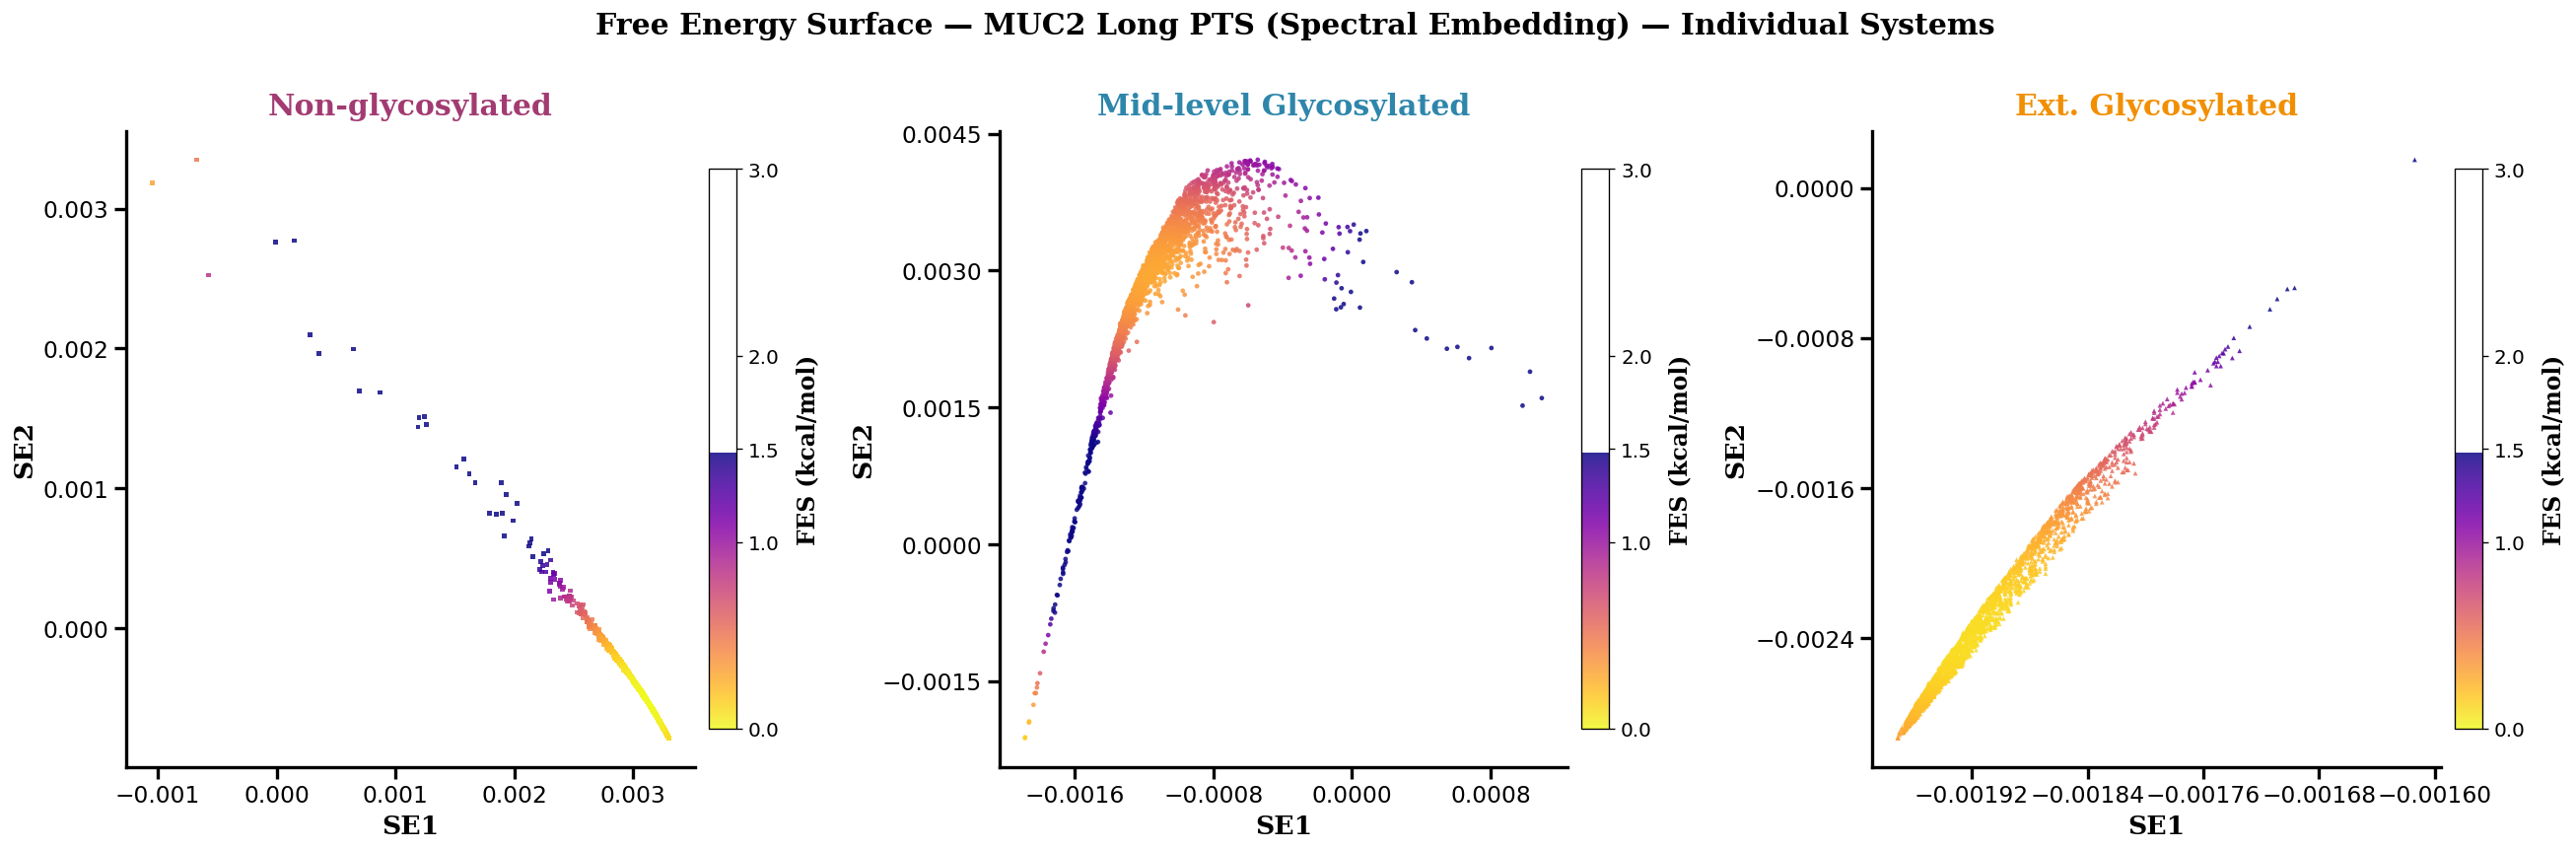

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/se_fes_individual.png


In [25]:
def _style_ax(ax):
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False);  ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

def plot_fes_individual(data_dict, vmax, xlabel, ylabel, coord_tag, outfile):
    """One panel per system (canonical order), publication-quality styling."""
    fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=120)
    fig.set_facecolor("white")

    for ax, (sys_key, label, clr, mkr) in zip(axes, SYS_INFO):
        x1, x2, fes = data_dict[sys_key]
        order = np.argsort(fes)[::-1]
        sc = ax.scatter(x1[order], x2[order], c=fes[order],
                        cmap="plasma_r", vmin=0, vmax=vmax,
                        s=8, alpha=0.85, linewidths=0, marker=mkr)
        cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
        cbar.set_label("FES (kcal/mol)", fontsize=14,
                       fontname="DejaVu Serif", fontweight="bold", labelpad=10)
        cbar.ax.tick_params(labelsize=12)
        cbar.set_ticks([0, 1, 2, 3, round(vmax, 1)])
        ax.set_title(label, fontsize=18, fontname="DejaVu Serif",
                     fontweight="bold", color=clr, pad=10)
        ax.set_xlabel(xlabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
        ax.set_ylabel(ylabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
        _style_ax(ax)

    fig.suptitle(f"Free Energy Surface \u2014 MUC2 Long PTS ({coord_tag}) \u2014 Individual Systems",
                 fontsize=18, fontname="DejaVu Serif", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

# SE individual only
plot_fes_individual(se_data, se_vmax, "SE1", "SE2",
                    "Spectral Embedding",
                    os.path.join(OUT_FES3, "se_fes_individual.png"))


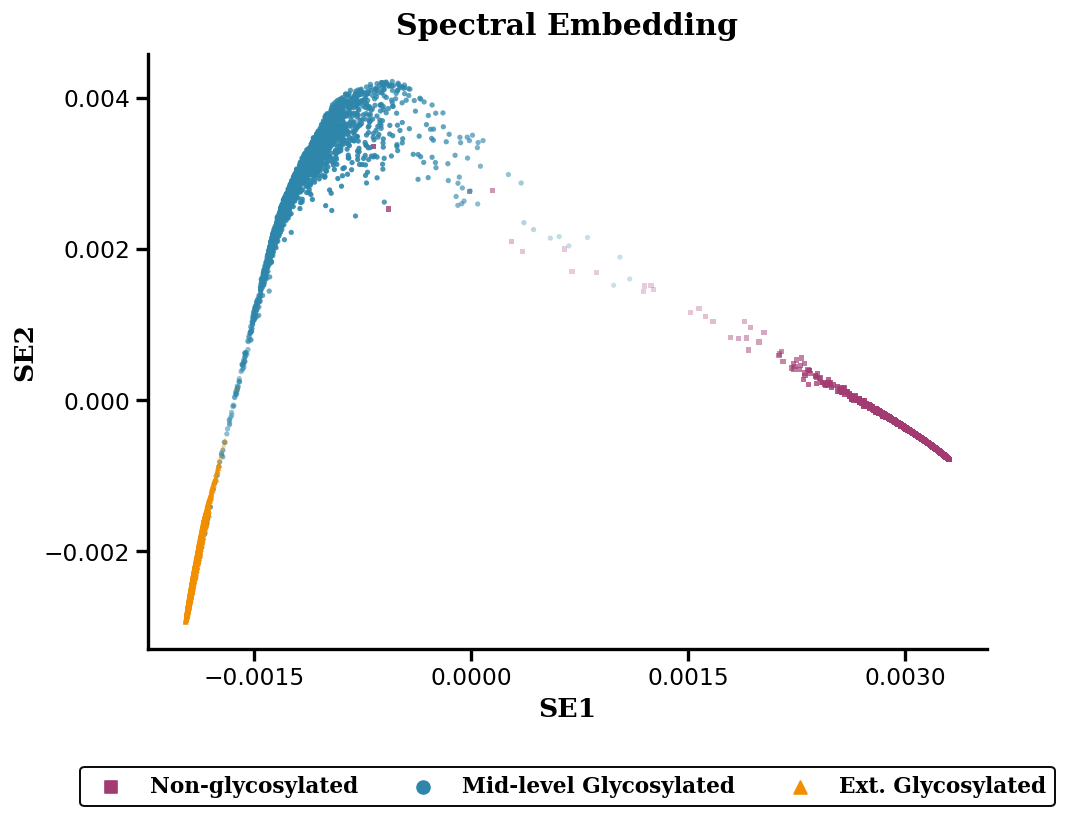

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/se_fes_group_scatter.png


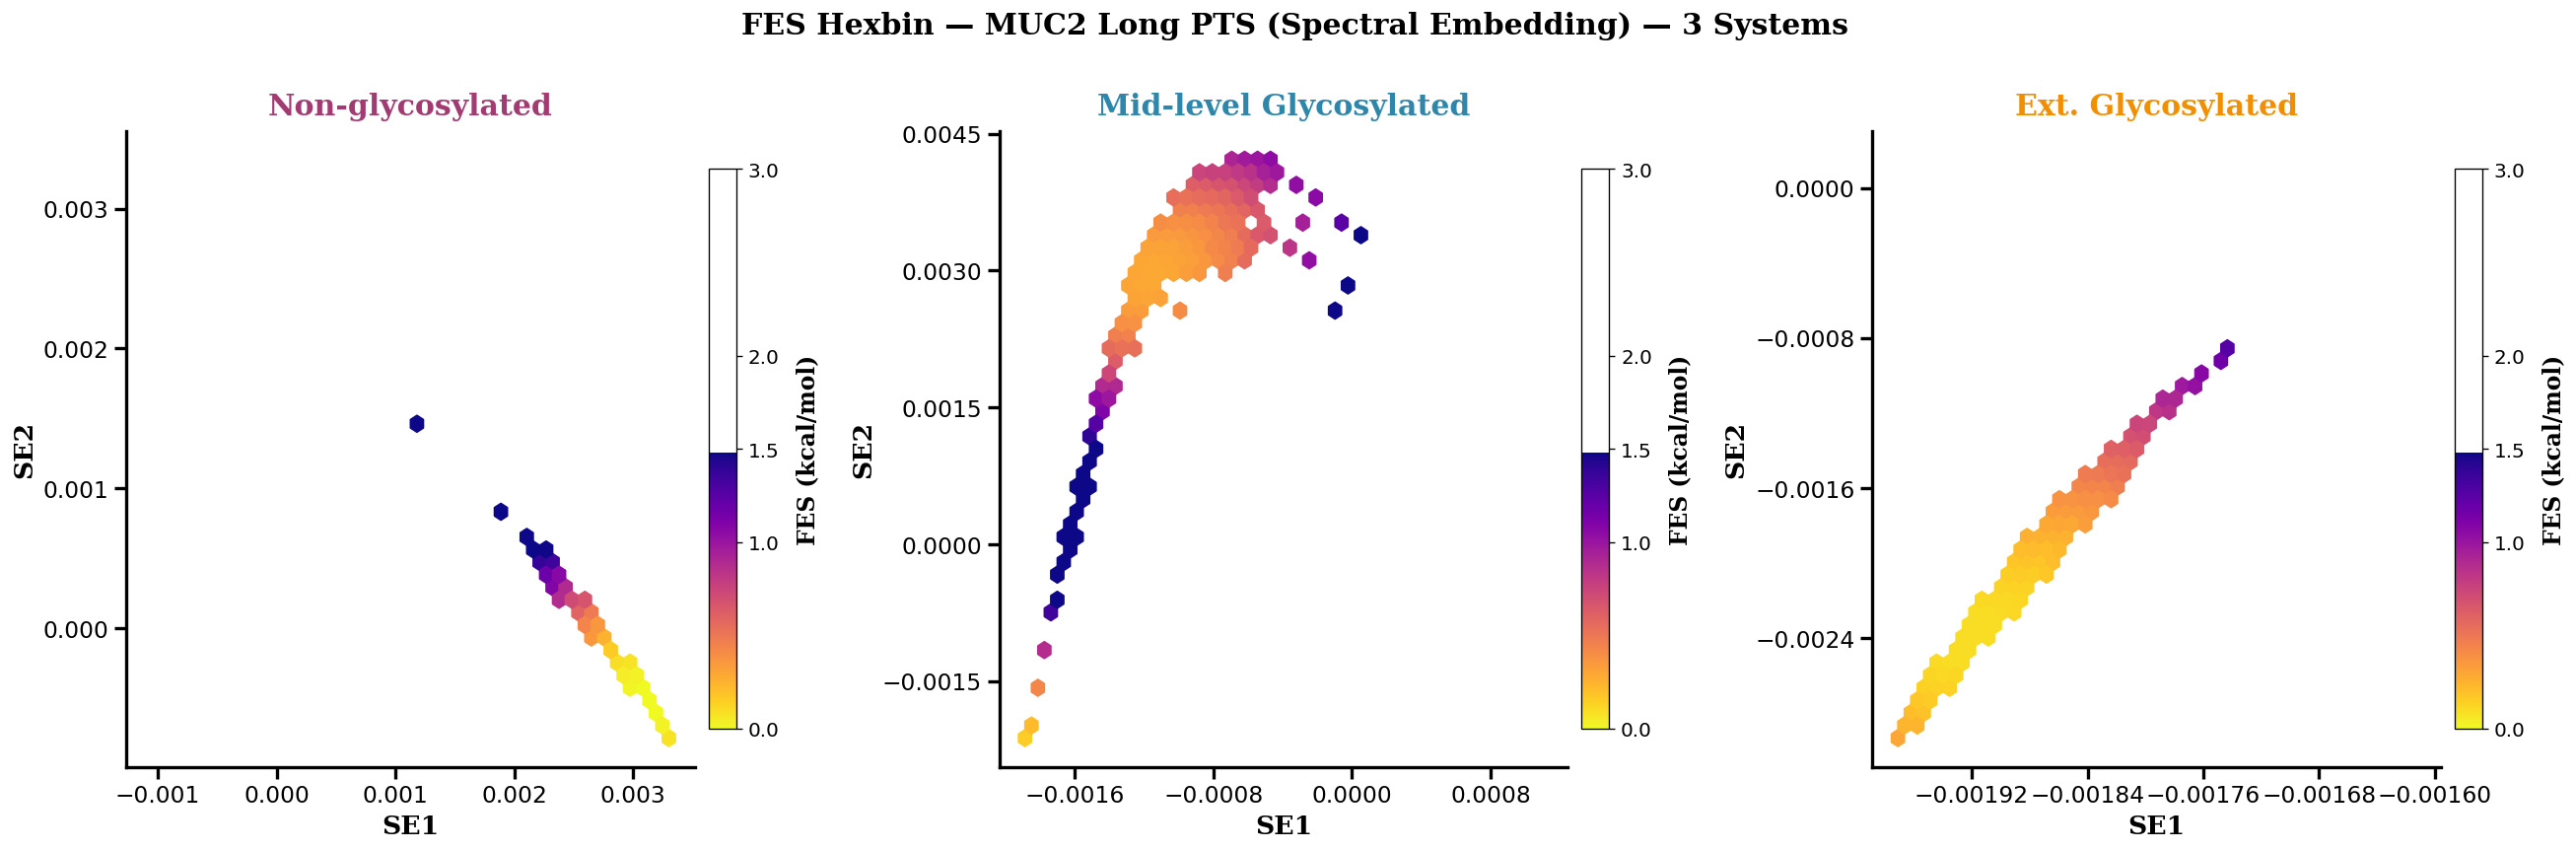

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/se_fes_group_hexbin.png


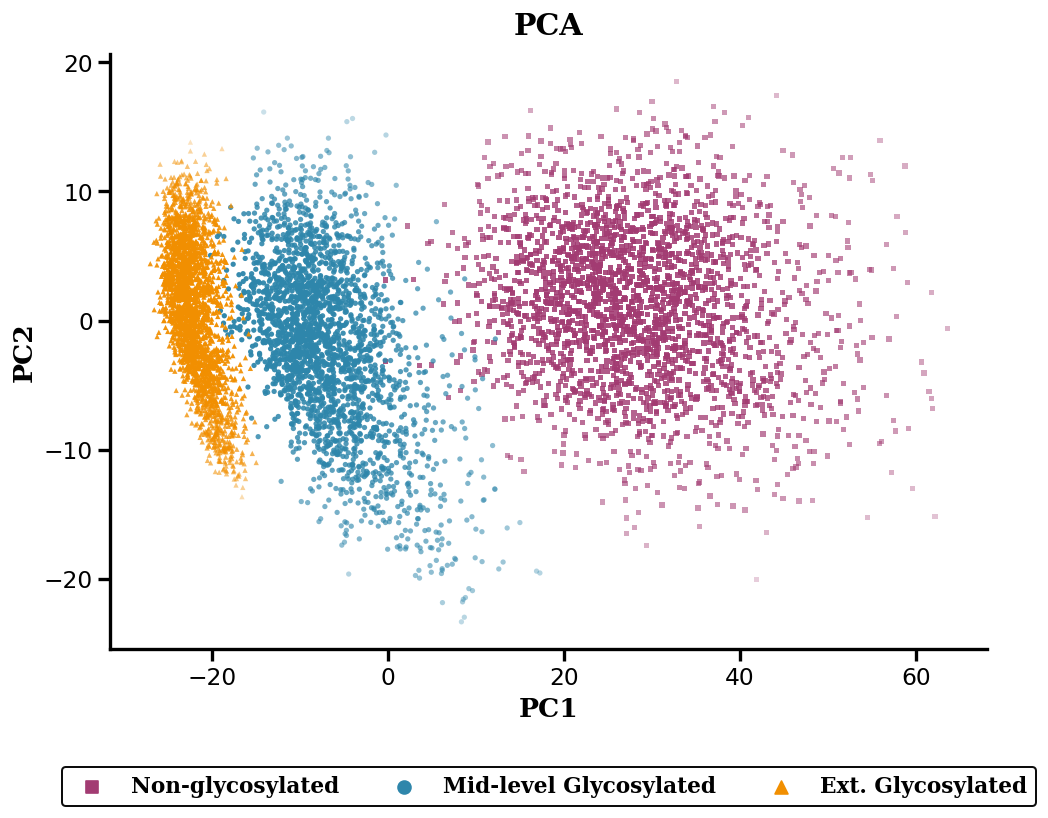

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/pca_fes_group_scatter.png


In [26]:
def plot_fes_group_scatter(data_dict, xlabel, ylabel, coord_tag, outfile):
    """All 3 systems on one axes — system colors, opacity encodes stability."""
    fig, ax = plt.subplots(figsize=(9, 7), dpi=120)
    fig.set_facecolor("white")

    for sys_key, label, clr, mkr in SYS_INFO:
        x1, x2, fes = data_dict[sys_key]
        fes_norm  = fes / fes.max()
        alpha_arr = 1.0 - 0.75 * fes_norm
        order = np.argsort(fes)[::-1]
        rgba = np.zeros((len(x1), 4))
        rgb  = plt.matplotlib.colors.to_rgb(clr)
        rgba[:, :3] = rgb
        rgba[:, 3]  = alpha_arr
        ax.scatter(x1[order], x2[order], color=rgba[order],
                   s=10, linewidths=0, marker=mkr)

    _style_ax(ax)

    # Marker legend — below x-axis
    handles = [plt.scatter([], [], s=60, marker=mkr, color=clr, label=lbl)
               for _, lbl, clr, mkr in SYS_INFO]
    leg = ax.legend(handles=handles, fontsize=13, frameon=True, framealpha=0.95,
                    edgecolor="black", ncol=3,
                    loc="upper center", bbox_to_anchor=(0.5, -0.18),
                    prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
    leg.get_frame().set_linewidth(1.2)

    ax.set_xlabel(xlabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(coord_tag,
                 fontsize=18, fontname="DejaVu Serif", fontweight="bold", pad=12)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

def plot_fes_group_hexbin(data_dict, vmax, xlabel, ylabel, coord_tag, outfile):
    """3-panel hexbin (one per system), plasma_r on min FES per hex."""
    fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=120)
    fig.set_facecolor("white")

    for ax, (sys_key, label, clr, mkr) in zip(axes, SYS_INFO):
        x1, x2, fes = data_dict[sys_key]
        hb = ax.hexbin(x1, x2, C=fes, reduce_C_function=np.min,
                       gridsize=40, cmap="plasma_r",
                       vmin=0, vmax=vmax, mincnt=1)
        ax.set_facecolor("white")
        cbar = plt.colorbar(hb, ax=ax, pad=0.02, shrink=0.88)
        cbar.set_label("FES (kcal/mol)", fontsize=14,
                       fontname="DejaVu Serif", fontweight="bold", labelpad=10)
        cbar.ax.tick_params(labelsize=12)
        cbar.set_ticks([0, 1, 2, 3, round(vmax, 1)])
        ax.set_title(label, fontsize=18, fontname="DejaVu Serif",
                     fontweight="bold", color=clr, pad=10)
        ax.set_xlabel(xlabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
        ax.set_ylabel(ylabel, fontsize=16, fontname="DejaVu Serif", fontweight="bold")
        _style_ax(ax)

    fig.suptitle(f"FES Hexbin — MUC2 Long PTS ({coord_tag}) — 3 Systems",
                 fontsize=18, fontname="DejaVu Serif", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

# SE group
plot_fes_group_scatter(se_data, "SE1", "SE2",
                       "Spectral Embedding",
                       os.path.join(OUT_FES3, "se_fes_group_scatter.png"))
plot_fes_group_hexbin(se_data, se_vmax, "SE1", "SE2",
                      "Spectral Embedding",
                      os.path.join(OUT_FES3, "se_fes_group_hexbin.png"))

# PCA group scatter only
plot_fes_group_scatter(pca_data, "PC1", "PC2",
                       "PCA",
                       os.path.join(OUT_FES3, "pca_fes_group_scatter.png"))


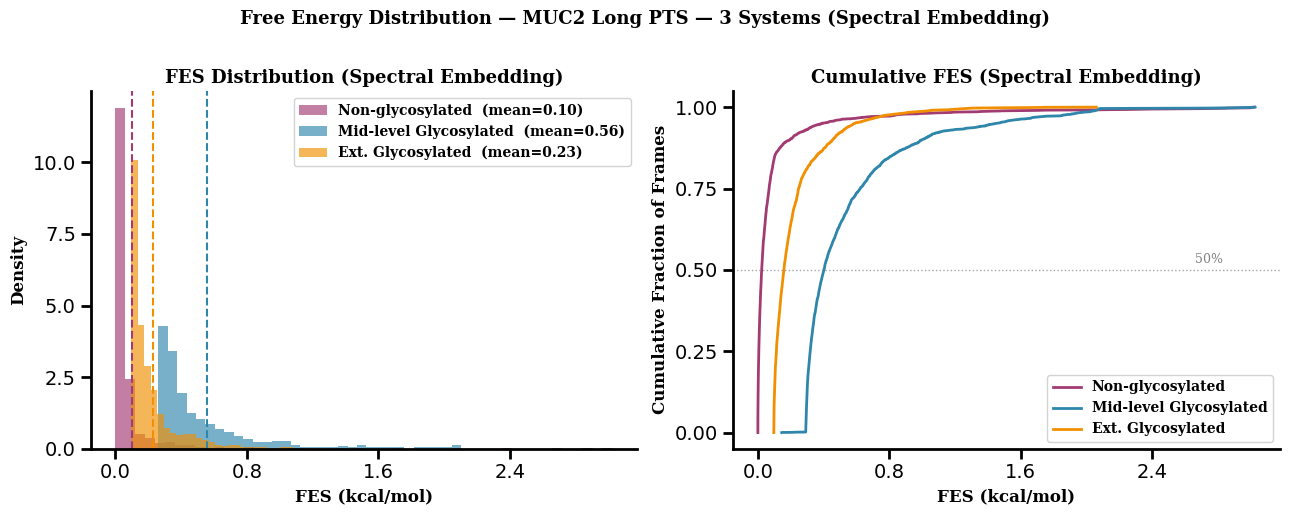

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/se_fes_distribution.png


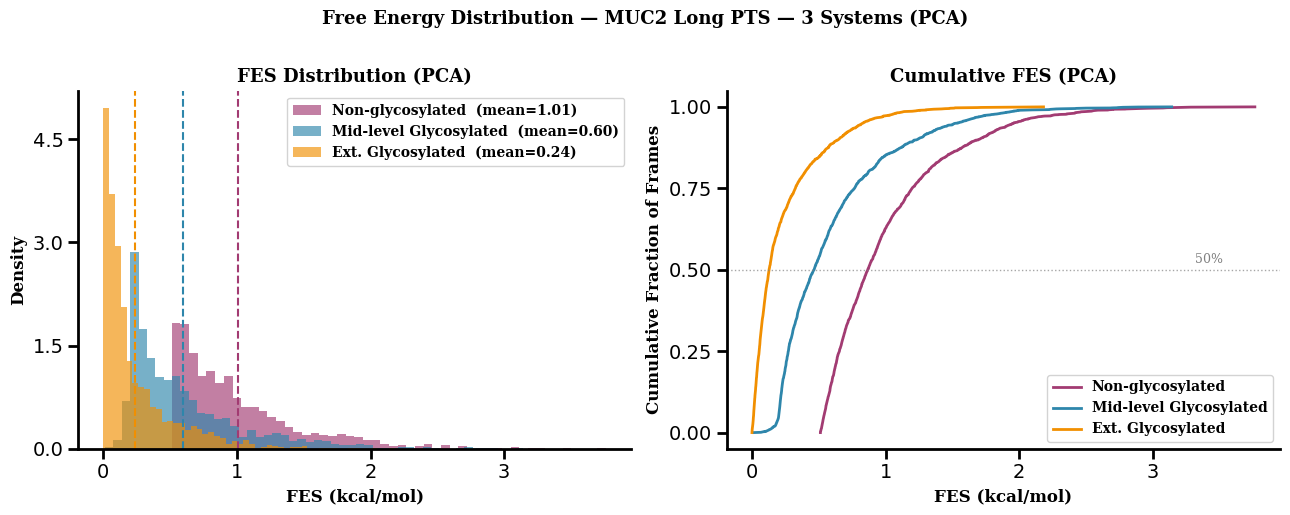

Saved: /home/computer2/analysis_simulations/analysis/pca_physical_vars/fes_3sys/pca_fes_distribution.png


In [27]:
def plot_fes_distribution(data_dict, vmax, coord_tag, outfile):
    """Histogram + CDF of FES for all 3 systems on one set of axes."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
    fig.set_facecolor("white")

    # Left: FES histogram (density)
    ax = axes[0]
    for sys_key, label, clr, mkr in SYS_INFO:
        _, _, fes = data_dict[sys_key]
        ax.hist(fes, bins=50, color=clr, alpha=0.65, density=True,
                label=f"{label}  (mean={fes.mean():.2f})")
        ax.axvline(fes.mean(), color=clr, linestyle="--", linewidth=1.5)
    ax.set_xlabel("FES (kcal/mol)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"FES Distribution ({coord_tag})", fontsize=13,
                 fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, framealpha=0.85,
              prop={"family": "DejaVu Serif", "weight": "bold"})
    _style_ax(ax)

    # Right: CDF
    ax = axes[1]
    x_max = 0.0
    for sys_key, label, clr, mkr in SYS_INFO:
        _, _, fes = data_dict[sys_key]
        fes_sorted = np.sort(fes)
        cdf = np.arange(1, len(fes_sorted) + 1) / len(fes_sorted)
        ax.plot(fes_sorted, cdf, color=clr, linewidth=2.0, label=label)
        x_max = max(x_max, fes_sorted[-1])

    ax.axhline(0.5, color="gray", linewidth=1.0, linestyle=":", alpha=0.7)
    # Fixed x position avoids xlim-not-set bug
    ax.text(x_max * 0.88, 0.52, "50%", fontsize=9, color="gray",
            fontname="DejaVu Serif")
    ax.set_xlabel("FES (kcal/mol)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Cumulative Fraction of Frames", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"Cumulative FES ({coord_tag})", fontsize=13,
                 fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=9, framealpha=0.85,
              prop={"family": "DejaVu Serif", "weight": "bold"})
    _style_ax(ax)

    plt.suptitle(f"Free Energy Distribution — MUC2 Long PTS — 3 Systems ({coord_tag})",
                 fontsize=13, fontname="DejaVu Serif", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {outfile}")

# SE distribution
plot_fes_distribution(se_data, se_vmax,
                      "Spectral Embedding",
                      os.path.join(OUT_FES3, "se_fes_distribution.png"))

# PCA distribution
plot_fes_distribution(pca_data, pca_vmax,
                      "PCA",
                      os.path.join(OUT_FES3, "pca_fes_distribution.png"))